# 01 — C-MAPSS Data Audit, EDA & Baseline RUL Model

**Project:** PdM-Live — IoT real-time predictive maintenance
**Plan steps covered:** `docs/06_Plan.md` P1.3 (load & name), P1.4 (audit → `data/reference/data_audit.json`), and an exploratory preview of P1.5–P1.8 (labels, features, leakage-safe CV, baseline vs. LightGBM, official test evaluation).

This notebook is the *readable* walkthrough of the data and modelling decisions documented in
`docs/05_ML_and_Data_Spec.md`. Production code will live in `ml/pdm_ml/`; anything here that becomes
production logic must be moved there (see `CLAUDE.md`: *one feature implementation*).

### What you will find
1. Setup and paths
2. Loading the raw files with a named schema
3. Integrity audit (and the errors in `readme.txt`)
4. Engine lifetimes
5. Sensor behaviour: constant sensors, degradation trends, operating regimes
6. Regime-wise normalisation
7. Which sensors carry degradation signal (and why FD003/FD004 look different)
8. RUL labels and the piecewise-linear cap
9. Causal feature engineering (same idea the online service will use)
10. Leakage-safe validation (split by engine, truncated evaluation)
11. Baseline (Ridge) vs. LightGBM — cross-validation
12. One-time evaluation on the official test sets (RMSE + NASA score)
13. Prediction intervals (quantile LightGBM) and error analysis
14. Writing `data/reference/data_audit.json`
15. Conclusions → what changes in the docs

### How to run
```bash
# from the repository root
uv venv --python 3.12 && source .venv/bin/activate
uv pip install numpy==2.2.6 pandas==2.3.3 scikit-learn==1.6.1 lightgbm==4.6.0 matplotlib==3.10.3 scipy==1.15.3 jupyterlab==4.4.3
jupyter lab ml/notebooks/01_data_audit_and_baseline.ipynb
```
Runtime: about 2–4 minutes on a laptop CPU. Random seeds are fixed (`SEED = 42`), so numbers are reproducible.

## 1. Setup

We locate the repository root by walking up from the notebook until we find `data/raw/cmapss/`.
This keeps the notebook runnable from any working directory.

In [1]:
from pathlib import Path
import json, hashlib, platform, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, lightgbm as lgb
from sklearn.cluster import KMeans
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
PROFILES = ["FD001", "FD002", "FD003", "FD004"]
RUL_CAP = 125          # piecewise-linear target cap (docs/05 §4)
WINDOW = 30            # feature window in cycles (docs/05 §5)
MIN_CYCLES = 5         # prediction gating: no RUL before 5 cycles
EWM_ALPHA = 0.3        # causal exponential smoothing factor

def find_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "data" / "raw" / "cmapss").is_dir():
            return p
    raise FileNotFoundError("Could not find data/raw/cmapss above " + str(start))

ROOT = find_root()
RAW = ROOT / "data" / "raw" / "cmapss"
REF = ROOT / "data" / "reference"
REF.mkdir(parents=True, exist_ok=True)

print("Repo root :", ROOT)
print("Python    :", platform.python_version())
print("pandas", pd.__version__, "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__)

Repo root : /tmp/repo
Python    : 3.13.18
pandas 2.3.3 | numpy 2.2.6 | sklearn 1.6.1 | lightgbm 4.6.0


## 2. Loading the raw files with a named schema

The raw files have **no header**, are **space-separated with trailing spaces**, and contain 26 columns:
unit, cycle, 3 operational settings and **21** sensors. Sensor names and units are not in the readme;
they come from Table 2 of `Damage Propagation Modeling.pdf`. We use the C-MAPSS symbols (e.g. `T30`)
as column names because the IoT payload contract (`docs/04_TRD.md` §5.2) uses the same keys.

In [2]:
SENSOR_CATALOG = pd.DataFrame([
    # raw,  symbol,      description,                          unit,      subsystem
    ("s1",  "T2",        "Total temperature at fan inlet",     "°R",      "Fan"),
    ("s2",  "T24",       "Total temperature at LPC outlet",    "°R",      "LPC"),
    ("s3",  "T30",       "Total temperature at HPC outlet",    "°R",      "HPC"),
    ("s4",  "T50",       "Total temperature at LPT outlet",    "°R",      "LPT"),
    ("s5",  "P2",        "Pressure at fan inlet",              "psia",    "Fan"),
    ("s6",  "P15",       "Total pressure in bypass duct",      "psia",    "Fan"),
    ("s7",  "P30",       "Total pressure at HPC outlet",       "psia",    "HPC"),
    ("s8",  "Nf",        "Physical fan speed",                 "rpm",     "Fan"),
    ("s9",  "Nc",        "Physical core speed",                "rpm",     "HPC"),
    ("s10", "epr",       "Engine pressure ratio (P50/P2)",     "-",       "Engine"),
    ("s11", "Ps30",      "Static pressure at HPC outlet",      "psia",    "HPC"),
    ("s12", "phi",       "Ratio of fuel flow to Ps30",         "pps/psi", "Burner"),
    ("s13", "NRf",       "Corrected fan speed",                "rpm",     "Fan"),
    ("s14", "NRc",       "Corrected core speed",               "rpm",     "HPC"),
    ("s15", "BPR",       "Bypass ratio",                       "-",       "Fan"),
    ("s16", "farB",      "Burner fuel-air ratio",              "-",       "Burner"),
    ("s17", "htBleed",   "Bleed enthalpy",                     "-",       "HPT"),
    ("s18", "Nf_dmd",    "Demanded fan speed",                 "rpm",     "Fan"),
    ("s19", "PCNfR_dmd", "Demanded corrected fan speed",       "rpm",     "Fan"),
    ("s20", "W31",       "HPT coolant bleed",                  "lbm/s",   "HPT"),
    ("s21", "W32",       "LPT coolant bleed",                  "lbm/s",   "LPT"),
], columns=["raw", "symbol", "description", "unit", "subsystem"])

SETTINGS = ["setting_1", "setting_2", "setting_3"]
SENSORS = SENSOR_CATALOG.symbol.tolist()
COLUMNS = ["unit", "cycle", *SETTINGS, *SENSORS]

def load_split(profile: str, split: str) -> pd.DataFrame:
    # split is "train" or "test"
    df = pd.read_csv(RAW / f"{split}_{profile}.txt", sep=r"\s+", header=None)
    assert df.shape[1] == 26, f"{split}_{profile}: expected 26 columns, got {df.shape[1]}"
    df.columns = COLUMNS
    return df.astype({"unit": int, "cycle": int})

def load_true_rul(profile: str) -> pd.Series:
    r = pd.read_csv(RAW / f"RUL_{profile}.txt", sep=r"\s+", header=None)[0]
    r.index = np.arange(1, len(r) + 1)   # test unit ids are 1..N in file order
    return r

train = {p: load_split(p, "train") for p in PROFILES}
test = {p: load_split(p, "test") for p in PROFILES}
true_rul = {p: load_true_rul(p) for p in PROFILES}

SENSOR_CATALOG.set_index("raw")

,symbol,description,unit,subsystem
raw,,,,
s1,T2,Total temperature at fan inlet,°R,Fan
s2,T24,Total temperature at LPC outlet,°R,LPC
s3,T30,Total temperature at HPC outlet,°R,HPC
s4,T50,Total temperature at LPT outlet,°R,LPT
s5,P2,Pressure at fan inlet,psia,Fan
s6,P15,Total pressure in bypass duct,psia,Fan
s7,P30,Total pressure at HPC outlet,psia,HPC
s8,Nf,Physical fan speed,rpm,Fan
s9,Nc,Physical core speed,rpm,HPC


In [3]:
train["FD001"].head()

,unit,cycle,setting_1,setting_2,setting_3,T2,T24,T30,T50,P2,P15,P30,Nf,Nc,epr,Ps30,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 3. Integrity audit

We check what `readme.txt` claims against what the files actually contain. Any mismatch is a
**quirk** that must be recorded in `docs/05_ML_and_Data_Spec.md` §11.

In [4]:
README_CLAIMS = {  # from readme.txt
    "FD001": (100, 100), "FD002": (260, 259), "FD003": (100, 100), "FD004": (248, 249),
}
rows = []
for p in PROFILES:
    tr, te, r = train[p], test[p], true_rul[p]
    contiguous = all(
        g.cycle.iloc[0] == 1 and (g.cycle.diff().dropna() == 1).all()
        for d in (tr, te) for _, g in d.groupby("unit")
    )
    rows.append({
        "profile": p,
        "train_rows": len(tr), "test_rows": len(te),
        "train_units": tr.unit.nunique(), "readme_train": README_CLAIMS[p][0],
        "test_units": te.unit.nunique(), "readme_test": README_CLAIMS[p][1],
        "rul_rows": len(r),
        "missing_values": int(tr.isna().sum().sum() + te.isna().sum().sum()),
        "cycles_contiguous_from_1": contiguous,
    })
integrity = pd.DataFrame(rows).set_index("profile")
integrity["readme_matches"] = (integrity.train_units == integrity.readme_train) & (integrity.test_units == integrity.readme_test)
integrity

,train_rows,test_rows,train_units,readme_train,test_units,readme_test,rul_rows,missing_values,cycles_contiguous_from_1,readme_matches
profile,,,,,,,,,,
FD001,20631,13096,100,100,100,100,100,0,True,True
FD002,53759,33991,260,260,259,259,259,0,True,True
FD003,24720,16596,100,100,100,100,100,0,True,True
FD004,61249,41214,249,248,248,249,248,0,True,False


**Findings**

* All files have 26 columns, no missing values, and every engine's cycles run 1, 2, 3, … without gaps.
* `RUL_FD00x.txt` always has exactly one row per test unit.
* **Readme error 1:** it lists columns up to "sensor measurement 26"; there are only **21** sensors (26 columns in total).
* **Readme error 2:** FD004 counts are **swapped** — the files have **249** training and **248** test engines (and `RUL_FD004.txt` has 248 rows).

## 4. Engine lifetimes

Training engines run until failure, so the last cycle of each unit *is* its lifetime. Test engines are cut
off early; the official target is the remaining cycles after that cut.

,train life min,train life median,train life max,test length min,test length median,test length max,true test RUL min,true test RUL median,true test RUL max
FD001,128.0,199.0,362.0,31.0,133.5,303.0,7.0,86.0,145.0
FD002,128.0,199.0,378.0,21.0,132.0,367.0,6.0,80.0,194.0
FD003,145.0,220.5,525.0,38.0,148.0,475.0,6.0,77.5,145.0
FD004,128.0,234.0,543.0,19.0,153.5,486.0,6.0,88.0,195.0


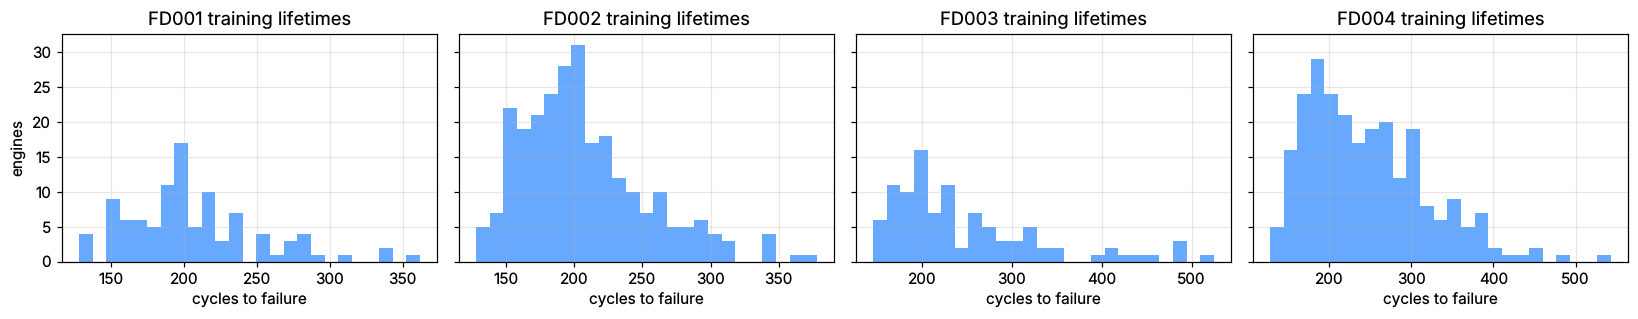

In [5]:
life = {p: train[p].groupby("unit").cycle.max() for p in PROFILES}
test_len = {p: test[p].groupby("unit").cycle.max() for p in PROFILES}

summary = pd.DataFrame({
    p: {
        "train life min": life[p].min(), "train life median": life[p].median(), "train life max": life[p].max(),
        "test length min": test_len[p].min(), "test length median": test_len[p].median(), "test length max": test_len[p].max(),
        "true test RUL min": true_rul[p].min(), "true test RUL median": true_rul[p].median(), "true test RUL max": true_rul[p].max(),
    } for p in PROFILES
}).T
display(summary)

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, p in zip(axes, PROFILES):
    ax.hist(life[p], bins=25, color="#4C9AFF", alpha=.85)
    ax.set_title(f"{p} training lifetimes"); ax.set_xlabel("cycles to failure")
axes[0].set_ylabel("engines")
plt.tight_layout(); plt.show()

Lifetimes are right-skewed (128 to 543 cycles). The shortest test series has only **19 cycles** (FD004), which is
why the feature pipeline must work with partial windows (minimum 5 cycles).

## 5. Sensor behaviour

### 5.1 Constant and low-information sensors
A sensor whose standard deviation is (almost) zero can't tell us anything about degradation.

In [6]:
const_rows = {}
for p in PROFILES:
    s = train[p][SETTINGS + SENSORS]
    const_rows[p] = {c: ("constant" if s[c].nunique() == 1 else f"{s[c].nunique()} values")
                     for c in SETTINGS + SENSORS if s[c].nunique() <= 10}
pd.DataFrame(const_rows).fillna("varies")

,FD001,FD002,FD003,FD004
setting_3,constant,2 values,constant,2 values
T2,constant,6 values,constant,6 values
P2,constant,6 values,constant,6 values
P15,2 values,varies,varies,varies
epr,constant,9 values,4 values,varies
farB,constant,2 values,constant,2 values
Nf_dmd,constant,6 values,constant,6 values
PCNfR_dmd,constant,2 values,constant,2 values


* In single-condition subsets (FD001/FD003) **T2, P2, farB, Nf_dmd, PCNfR_dmd** (and **epr** in FD001) never change.
* **P15** in FD001 only takes 2 values (21.60 / 21.61) — it's quantised, so practically uninformative.
* In FD002/FD004 these "constant" sensors take exactly one value per operating condition, i.e. they encode the
  *flight condition*, not degradation.
* Nf_dmd and PCNfR_dmd are **control setpoints** (demanded speeds), not measurements.

### 5.2 What degradation looks like (FD001)
We plot a few sensors for 5 engines against *cycles before failure*, so all engines end at 0.

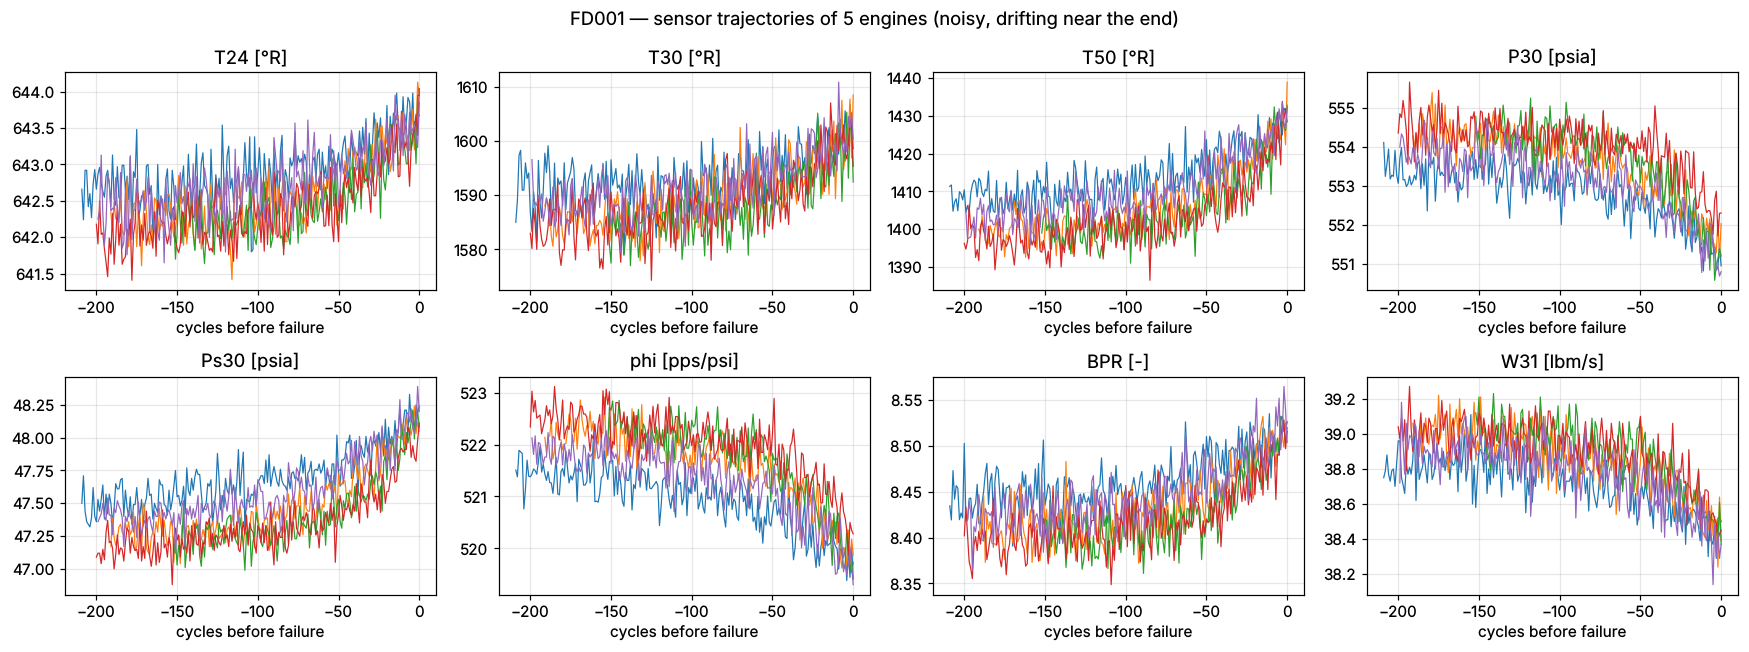

In [7]:
rng = np.random.default_rng(SEED)
demo_units = rng.choice(train["FD001"].unit.unique(), 5, replace=False)
show = ["T24", "T30", "T50", "P30", "Ps30", "phi", "BPR", "W31"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, s in zip(axes.ravel(), show):
    for u in demo_units:
        g = train["FD001"][train["FD001"].unit == u]
        ax.plot(g.cycle - g.cycle.max(), g[s], lw=.8)
    unit = SENSOR_CATALOG.set_index("symbol").loc[s, "unit"]
    ax.set_title(f"{s} [{unit}]"); ax.set_xlabel("cycles before failure")
fig.suptitle("FD001 — sensor trajectories of 5 engines (noisy, drifting near the end)")
plt.tight_layout(); plt.show()

Signals are **noisy** (the PDF describes a mixture of process and measurement noise) and stay flat for most of the
life, then drift in the last ~100 cycles. That motivates two decisions: **smoothing/window features** and a
**capped RUL target** (section 8).

### 5.3 Operating regimes (FD002 / FD004)
The three operational settings form **six discrete flight conditions**. The same healthy engine reads completely
different values in different conditions, so raw sensor values aren't comparable across rows.

,,,rows
setting_1,setting_2,setting_3,
42.0,0.84,100.0,13458
20.0,0.70,100.0,8122
10.0,0.25,100.0,8096
0.0,0.00,100.0,8044
35.0,0.84,100.0,8037
25.0,0.62,60.0,8002


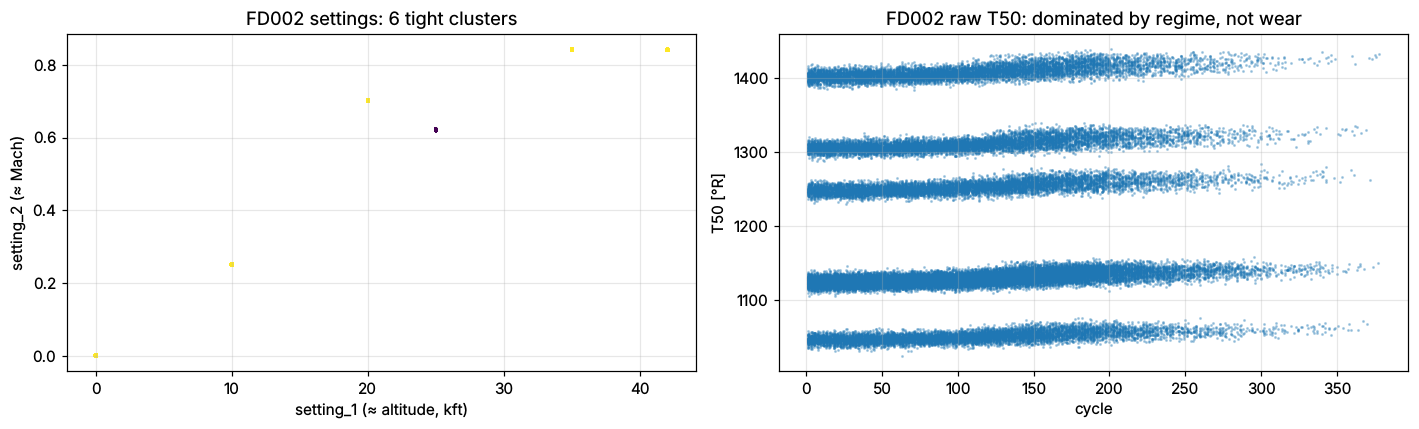

FD001 setting ranges (single condition, only noise):
     setting_1  setting_2  setting_3
min    -0.0087    -0.0006      100.0
max     0.0087     0.0006      100.0


In [8]:
reg = train["FD002"][SETTINGS].round({"setting_1": 0, "setting_2": 2, "setting_3": 0}).value_counts()
display(reg.rename("rows").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
d = train["FD002"]
axes[0].scatter(d.setting_1, d.setting_2, s=2, c=d.setting_3, cmap="viridis")
axes[0].set_xlabel("setting_1 (≈ altitude, kft)"); axes[0].set_ylabel("setting_2 (≈ Mach)")
axes[0].set_title("FD002 settings: 6 tight clusters")
axes[1].scatter(d.cycle, d.T50, s=1, alpha=.3)
axes[1].set_xlabel("cycle"); axes[1].set_ylabel("T50 [°R]"); axes[1].set_title("FD002 raw T50: dominated by regime, not wear")
plt.tight_layout(); plt.show()

print("FD001 setting ranges (single condition, only noise):")
print(train["FD001"][SETTINGS].agg(["min", "max"]))

## 6. Regime-wise normalisation

**Rule (docs/05 §5):** assign every row to a regime (KMeans with k=6 on the settings for FD002/FD004; a
single regime for FD001/FD003), then z-score each sensor *within its regime*, using statistics from
**training engines only**. We wrap this in a small fit/transform class so cross-validation can refit it on each fold.

regime sizes: {0: 13458, 1: 8044, 2: 8122, 3: 8002, 4: 8096, 5: 8037}


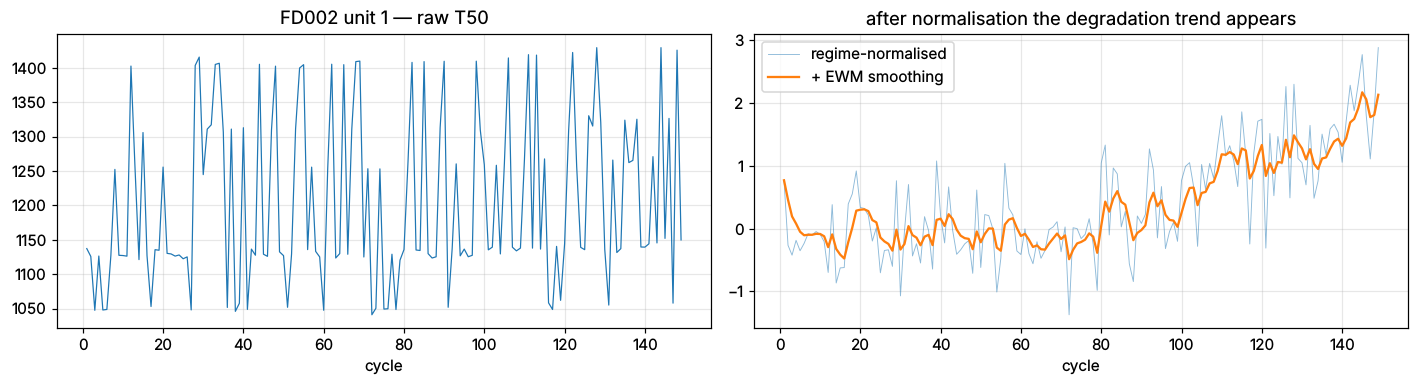

In [9]:
BASE_INPUTS = ["T24", "T30", "T50", "P30", "Nf", "Nc", "Ps30", "phi", "NRf", "NRc", "BPR", "htBleed", "W31", "W32"]
INPUTS = {"FD001": BASE_INPUTS, "FD002": BASE_INPUTS, "FD003": BASE_INPUTS + ["epr"], "FD004": BASE_INPUTS + ["epr"]}
MULTI_REGIME = {"FD002", "FD004"}

class RegimeNormalizer:
    # Fit on training engines only; transform adds a `regime` column and z-scores sensors per regime.
    def __init__(self, profile: str, sensors: list[str]):
        self.profile, self.sensors = profile, sensors

    def fit(self, df: pd.DataFrame):
        if self.profile in MULTI_REGIME:
            self.s_mean, self.s_std = df[SETTINGS].mean(), df[SETTINGS].std()
            self.km = KMeans(n_clusters=6, n_init=10, random_state=SEED).fit((df[SETTINGS] - self.s_mean) / self.s_std)
        regimes = self._regime(df)
        g = df[self.sensors].groupby(regimes)
        self.mu, self.sd = g.mean(), g.std().replace(0, np.nan)
        return self

    def _regime(self, df):
        if self.profile not in MULTI_REGIME:
            return pd.Series(0, index=df.index)
        return pd.Series(self.km.predict((df[SETTINGS] - self.s_mean) / self.s_std), index=df.index)

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        out = df.copy()
        out["regime"] = self._regime(df)
        mu = self.mu.loc[out.regime].to_numpy(); sd = self.sd.loc[out.regime].to_numpy()
        out[self.sensors] = (df[self.sensors].to_numpy() - mu) / sd
        return out

norm = RegimeNormalizer("FD002", INPUTS["FD002"]).fit(train["FD002"])
z = norm.transform(train["FD002"])
print("regime sizes:", z.regime.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
u = z[z.unit == 1]; raw = train["FD002"][train["FD002"].unit == 1]
axes[0].plot(raw.cycle, raw.T50, lw=.8); axes[0].set_title("FD002 unit 1 — raw T50"); axes[0].set_xlabel("cycle")
axes[1].plot(u.cycle, u.T50, lw=.6, alpha=.5, label="regime-normalised")
axes[1].plot(u.cycle, u.T50.ewm(alpha=EWM_ALPHA, adjust=False).mean(), lw=1.5, label="+ EWM smoothing")
axes[1].set_title("after normalisation the degradation trend appears"); axes[1].legend(); axes[1].set_xlabel("cycle")
plt.tight_layout(); plt.show()

## 7. Which sensors carry degradation signal?

We correlate each regime-normalised sensor with the capped RUL. Negative = the value rises as the engine wears.

In [10]:
def add_train_rul(df):
    out = df.copy()
    out["rul"] = out.groupby("unit").cycle.transform("max") - out.cycle
    out["rul_capped"] = out.rul.clip(upper=RUL_CAP)
    return out

corr = {}
for p in PROFILES:
    zz = add_train_rul(RegimeNormalizer(p, SENSORS).fit(train[p]).transform(train[p]))
    corr[p] = zz[SENSORS].corrwith(zz.rul_capped)
corr = pd.DataFrame(corr).round(2)
corr.style.background_gradient(cmap="RdBu", vmin=-.8, vmax=.8).format(na_rep="const")

,FD001,FD002,FD003,FD004
T2,const,const,const,const
T24,-0.680000,-0.630000,-0.680000,-0.580000
T30,-0.660000,-0.620000,-0.700000,-0.650000
T50,-0.760000,-0.740000,-0.770000,-0.720000
P2,const,const,const,const
P15,-0.110000,-0.360000,-0.100000,-0.120000
P30,0.730000,0.510000,-0.360000,-0.340000
Nf,-0.620000,-0.480000,-0.630000,-0.570000
Nc,-0.460000,-0.420000,-0.640000,-0.620000
epr,const,0.040000,-0.490000,-0.360000


**Findings**

* 14 sensors correlate strongly (|r| ≈ 0.4–0.8) in FD001/FD002: T24, T30, T50, P30, Nf, Nc, Ps30, phi, NRf, NRc,
  BPR, htBleed, W31, W32. This is the **base input set**.
* In **FD003/FD004** (two fault modes: HPC + Fan) **P30, phi, BPR, W31, W32 lose or flip** their correlation.
  HPC and Fan degradation push them in *opposite* directions, so globally they cancel out — but per engine they
  show *which* fault is developing. **We keep them**; a tree model can use the interaction.
* **epr** becomes informative in FD003/FD004 (r ≈ −0.4 to −0.5) and is added there.

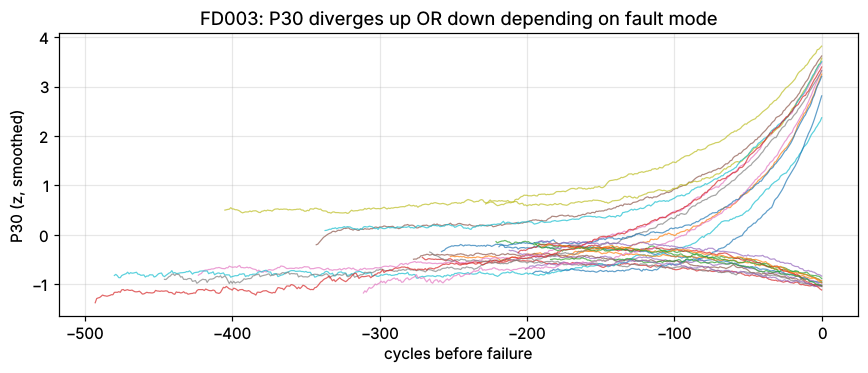

In [11]:
# Visual proof of the sign flip: P30 (smoothed) for FD003 engines ends either high or low.
zz = RegimeNormalizer("FD003", SENSORS).fit(train["FD003"]).transform(train["FD003"])
fig, ax = plt.subplots(figsize=(8, 3.5))
for u in zz.unit.unique()[:25]:
    g = zz[zz.unit == u]
    ax.plot(g.cycle - g.cycle.max(), g.P30.ewm(alpha=.1, adjust=False).mean(), lw=.8, alpha=.7)
ax.set_xlabel("cycles before failure"); ax.set_ylabel("P30 (z, smoothed)")
ax.set_title("FD003: P30 diverges up OR down depending on fault mode")
plt.tight_layout(); plt.show()

## 8. RUL labels and the piecewise-linear cap

* Train label: `RUL = last_cycle(unit) − cycle`.
* Early in life the engine is healthy and **degradation isn't observable** (the PDF says the health index starts
  between 0.99 and 1.0), so asking the model to tell RUL=300 from RUL=200 is asking it to learn noise.
  We cap the target: `RUL_target = min(RUL, 125)`.
* Test label per row (used for replay plots): `RUL = RUL_file[unit] + (last_cycle − cycle)`.

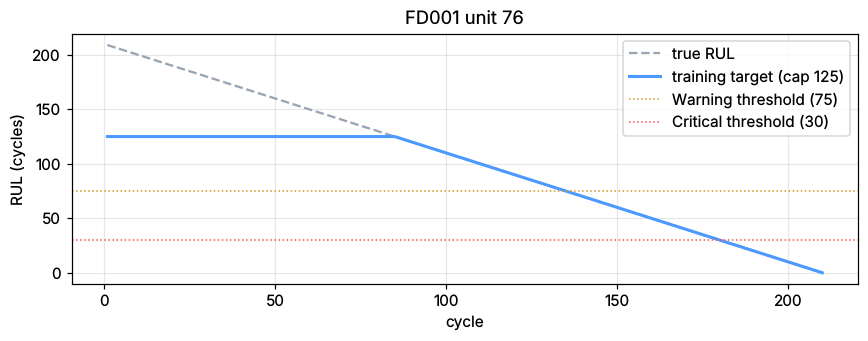

In [12]:
g = add_train_rul(train["FD001"]); g = g[g.unit == demo_units[0]]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(g.cycle, g.rul, label="true RUL", color="#9AA5B4", ls="--")
ax.plot(g.cycle, g.rul_capped, label=f"training target (cap {RUL_CAP})", color="#4C9AFF", lw=2)
ax.axhline(75, color="#D29922", lw=1, ls=":", label="Warning threshold (75)")
ax.axhline(30, color="#F85149", lw=1, ls=":", label="Critical threshold (30)")
ax.set_xlabel("cycle"); ax.set_ylabel("RUL (cycles)"); ax.legend(); ax.set_title(f"FD001 unit {demo_units[0]}")
plt.tight_layout(); plt.show()

## 9. Causal feature engineering

Every feature at cycle *t* uses **only cycles ≤ t of the same engine**, which is exactly what the online service
can compute from a rolling buffer when an ESP32 or replay sends one cycle at a time.

Per input sensor (after regime normalisation):

| feature | meaning |
|---|---|
| `ewm` | exponentially weighted mean (α = 0.3) — denoised current level |
| `mean` | mean of the last 30 cycles (or fewer if not yet available) |
| `std` | standard deviation over the last 30 cycles |
| `slope` | least-squares slope over the last 30 cycles (trend speed) |
| `delta` | `ewm` minus the engine's own first-5-cycle mean (drift from its own baseline; handles unit-to-unit initial wear) |

Plus `cycle` and `window_len`. Rows with fewer than 5 cycles are dropped (the dashboard shows "Warming up").

In [13]:
def window_features(z: pd.DataFrame, sensors: list[str]) -> pd.DataFrame:
    # z: regime-normalised frame sorted by unit, cycle. Returns one feature row per input row.
    z = z.sort_values(["unit", "cycle"]).reset_index(drop=True)
    g = z.groupby("unit", sort=False)
    t = z.cycle.astype(float)
    feats = {"unit": z.unit, "cycle": z.cycle, "window_len": g.cycle.transform(lambda c: np.minimum(np.arange(1, len(c) + 1), WINDOW))}
    roll = lambda s: s.groupby(z.unit, sort=False).rolling(WINDOW, min_periods=1)
    t_mean = roll(t).mean().reset_index(level=0, drop=True)
    t2_mean = roll(t * t).mean().reset_index(level=0, drop=True)
    var_t = (t2_mean - t_mean ** 2).replace(0, np.nan)
    for s in sensors:
        x = z[s]
        ewm = g[s].transform(lambda v: v.ewm(alpha=EWM_ALPHA, adjust=False).mean())
        m = roll(x).mean().reset_index(level=0, drop=True)
        sd = roll(x).std().reset_index(level=0, drop=True)
        xt = roll(x * t).mean().reset_index(level=0, drop=True)
        base = g[s].transform(lambda v: v.expanding().mean().where(np.arange(len(v)) < MIN_CYCLES).ffill())
        feats[f"{s}_ewm"] = ewm
        feats[f"{s}_mean"] = m
        feats[f"{s}_std"] = sd.fillna(0)
        feats[f"{s}_slope"] = ((xt - m * t_mean) / var_t).fillna(0)
        feats[f"{s}_delta"] = ewm - base
    out = pd.DataFrame(feats)
    return out[out.cycle >= MIN_CYCLES].reset_index(drop=True)

def feature_cols(sensors):
    return ["cycle", "window_len"] + [f"{s}_{k}" for s in sensors for k in ("ewm", "mean", "std", "slope", "delta")]

# Causality check: features for the first 50 cycles must not change when later cycles are appended.
p = "FD001"; nz = RegimeNormalizer(p, INPUTS[p]).fit(train[p])
full = window_features(nz.transform(train[p][train[p].unit == 1]), INPUTS[p])
part = window_features(nz.transform(train[p][(train[p].unit == 1) & (train[p].cycle <= 50)]), INPUTS[p])
assert np.allclose(full.iloc[:len(part)][feature_cols(INPUTS[p])], part[feature_cols(INPUTS[p])]), "feature leak from the future!"
print("Causality check passed —", len(feature_cols(INPUTS[p])), "features per row for", p)
full.head()

Causality check passed — 72 features per row for FD001


,unit,cycle,window_len,T24_ewm,T24_mean,T24_std,T24_slope,T24_delta,T30_ewm,T30_mean,T30_std,T30_slope,T30_delta,T50_ewm,T50_mean,T50_std,T50_slope,T50_delta,P30_ewm,P30_mean,...,BPR_ewm,BPR_mean,BPR_std,BPR_slope,BPR_delta,htBleed_ewm,htBleed_mean,htBleed_std,htBleed_slope,htBleed_delta,W31_ewm,W31_mean,W31_std,W31_slope,W31_delta,W32_ewm,W32_mean,W32_std,W32_slope,W32_delta
0,1,5,5,-0.945432,-0.945766,0.469503,0.259972,0.000334,-0.711521,-0.569733,0.664749,-0.370730,-0.141788,-0.621127,-0.636377,0.239922,0.110770,0.015251,0.932919,0.899668,...,-0.784770,-0.768046,0.691977,-0.116784,-0.016724,-0.777817,-0.910826,0.707303,0.129135,0.133009,0.750141,0.784134,0.407315,-0.243435,-0.033992,0.969243,0.954400,0.309451,-0.072886,0.014843
1,1,6,6,-1.010326,-0.981762,0.429093,0.117702,-0.064559,-0.794246,-0.639323,0.618522,-0.271494,-0.224513,-0.786891,-0.725927,0.306863,-0.013459,-0.150514,1.094451,0.994950,...,-0.800070,-0.779333,0.619540,-0.076409,-0.032024,-0.972682,-0.996916,0.666852,0.000000,-0.061856,0.796854,0.804420,0.367686,-0.121717,0.012721,0.892403,0.914185,0.293789,-0.076119,-0.061997
2,1,7,7,-0.827775,-0.898914,0.448866,0.135700,0.117991,-0.468050,-0.506123,0.665585,-0.069784,0.101683,-0.922925,-0.799414,0.340988,-0.063527,-0.286547,1.095671,1.009745,...,-0.917965,-0.838436,0.586780,-0.092083,-0.149920,-0.915385,-0.966170,0.614161,0.023060,-0.004558,1.028727,0.913755,0.443103,0.005928,0.244594,0.867713,0.899316,0.271061,-0.058726,-0.086687
3,1,8,8,-0.651995,-0.816780,0.476095,0.145223,0.293771,-0.697702,-0.597053,0.667729,-0.107142,-0.127969,-0.911489,-0.810088,0.317134,-0.049468,-0.275111,0.930440,0.951640,...,-0.918903,-0.848768,0.544038,-0.068277,-0.150858,-1.068979,-1.023820,0.591521,-0.023060,-0.158153,0.975267,0.905851,0.410842,-0.001317,0.191133,0.665306,0.811029,0.354026,-0.098009,-0.289094
4,1,9,9,-0.792921,-0.850665,0.456800,0.081325,0.152846,-0.466036,-0.522434,0.663507,-0.030228,0.103697,-1.109137,-0.894558,0.390152,-0.085309,-0.472759,0.760547,0.886361,...,-1.197922,-0.959901,0.608388,-0.114474,-0.429877,-0.982793,-0.996916,0.559172,0.000000,-0.071967,1.070627,0.948882,0.405410,0.024897,0.286493,0.789669,0.840898,0.343070,-0.050685,-0.164731


## 10. Leakage-safe validation

Three ways this dataset commonly leaks, and how we prevent each:

1. **Row-level random split** puts cycle 100 of an engine in training and cycle 101 in validation → near-perfect,
   meaningless scores. ✅ We split by **engine** with `GroupKFold(5)`.
2. **Preprocessing fitted on all data** (scalers, regime clusters) sees validation engines. ✅ The normaliser is
   **refit inside each fold** on fold-train engines only.
3. **Tuning on the official test set.** ✅ The `test_FD00x` / `RUL_FD00x` files are touched **once**, in section 12.

Test engines are cut off before failure, so validation mimics that: for every validation engine we sample
5 random **truncation points** and score the prediction at that cycle against the true remaining life.

In [14]:
LGB_PARAMS = dict(objective="regression", learning_rate=0.05, num_leaves=31, min_child_samples=20,
                  feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                  seed=SEED, verbose=-1, n_jobs=-1)

def nasa_score(pred, true):
    d = np.asarray(pred) - np.asarray(true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def rmse(pred, true):
    return float(np.sqrt(np.mean((np.asarray(pred) - np.asarray(true)) ** 2)))

def build(profile, fit_df, apply_df):
    # Fit normaliser on fit_df only, return features for apply_df.
    nz = RegimeNormalizer(profile, INPUTS[profile]).fit(fit_df)
    return window_features(nz.transform(apply_df), INPUTS[profile])

def truncation_sample(feat_df, life_s, n=5, rng=None):
    # Pick n truncation rows per engine with cycle in [min(31, life), life].
    rows = []
    for u, g in feat_df.groupby("unit"):
        lo = min(31, life_s[u]); cand = g[g.cycle >= lo]
        rows.append(cand.sample(min(n, len(cand)), random_state=int(rng.integers(1e9))))
    return pd.concat(rows)

def cross_validate(profile, n_splits=5):
    df = train[profile]; units = df.unit.to_numpy(); L = life[profile]
    cols = feature_cols(INPUTS[profile]); rng = np.random.default_rng(SEED)
    res = {"ridge": [], "lgbm": [], "best_iter": []}
    for k, (tr_idx, va_idx) in enumerate(GroupKFold(n_splits).split(df, groups=units)):
        tr_df, va_df = df.iloc[tr_idx], df.iloc[va_idx]
        Ftr, Fva = build(profile, tr_df, tr_df), build(profile, tr_df, va_df)
        ytr = (Ftr.unit.map(L) - Ftr.cycle).clip(upper=RUL_CAP)
        Fva_t = truncation_sample(Fva, L, rng=rng)
        # Score against the CAPPED truth: early truncation points can have true RUL of 300-500 cycles,
        # which no capped model can (or needs to) predict; official test truths are mostly <= 150.
        yva_t = (Fva_t.unit.map(L) - Fva_t.cycle).clip(upper=RUL_CAP)
        yva_all = (Fva.unit.map(L) - Fva.cycle).clip(upper=RUL_CAP)
        # Ridge baseline (on scaled features; tree model doesn't need scaling)
        mu, sd = Ftr[cols].mean(), Ftr[cols].std().replace(0, 1)
        ridge = RidgeCV(alphas=np.logspace(-2, 3, 12)).fit((Ftr[cols] - mu) / sd, ytr)
        res["ridge"].append(rmse(np.clip(ridge.predict((Fva_t[cols] - mu) / sd), 0, RUL_CAP), yva_t))
        # LightGBM with early stopping on the fold's validation engines
        m = lgb.train(LGB_PARAMS, lgb.Dataset(Ftr[cols], ytr), num_boost_round=2000,
                      valid_sets=[lgb.Dataset(Fva[cols], yva_all)],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
        res["lgbm"].append(rmse(np.clip(m.predict(Fva_t[cols], num_iteration=m.best_iteration), 0, RUL_CAP), yva_t))
        res["best_iter"].append(m.best_iteration)
    return {k: np.array(v) for k, v in res.items()}

## 11. Baseline (Ridge) vs. LightGBM — cross-validation

RMSE (cycles) at truncation points on held-out engines, against the **capped** truth, mean ± std over 5 folds.
*Note:* early stopping uses the fold's validation engines; that makes CV slightly optimistic. The official test
evaluation in section 12 has no such issue because it uses the averaged iteration count, not the test data.

In [15]:
cv = {p: cross_validate(p) for p in PROFILES}
cv_table = pd.DataFrame({
    p: {"Ridge RMSE": f"{c['ridge'].mean():.1f} ± {c['ridge'].std():.1f}",
        "LightGBM RMSE": f"{c['lgbm'].mean():.1f} ± {c['lgbm'].std():.1f}",
        "improvement vs Ridge": f"{100 * (1 - c['lgbm'].mean() / c['ridge'].mean()):.0f}%",
        "avg best iteration": int(c["best_iter"].mean())}
    for p, c in cv.items()}).T
cv_table

,Ridge RMSE,LightGBM RMSE,improvement vs Ridge,avg best iteration
FD001,17.2 ± 1.1,10.5 ± 1.2,39%,348
FD002,17.5 ± 0.7,12.2 ± 1.0,31%,268
FD003,16.3 ± 1.1,10.4 ± 0.8,36%,343
FD004,18.0 ± 0.5,13.7 ± 0.8,24%,274


## 12. One-time evaluation on the official test sets

For each profile: refit the normaliser and LightGBM on **all** training engines (iteration count = CV average),
then predict at the **last available cycle** of every test engine and compare with `RUL_FD00x.txt`.

Targets from `docs/01_PRD.md` §4.1: RMSE ≤ 16 (FD001, FD003), ≤ 22 (FD002), ≤ 24 (FD004), and ≥ 15% better than Ridge.

In [16]:
TARGET_RMSE = {"FD001": 16, "FD002": 22, "FD003": 16, "FD004": 24}
TARGET_SCORE = {"FD001": 500, "FD002": 3000, "FD003": 600, "FD004": 4500}
final_models, test_preds, results = {}, {}, []

for p in PROFILES:
    cols = feature_cols(INPUTS[p]); L = life[p]
    Ftr = build(p, train[p], train[p]); ytr = (Ftr.unit.map(L) - Ftr.cycle).clip(upper=RUL_CAP)
    n_iter = int(cv[p]["best_iter"].mean())
    point = lgb.train(LGB_PARAMS, lgb.Dataset(Ftr[cols], ytr), num_boost_round=n_iter)
    q = {a: lgb.train({**LGB_PARAMS, "objective": "quantile", "alpha": a}, lgb.Dataset(Ftr[cols], ytr), num_boost_round=n_iter)
         for a in (0.1, 0.9)}
    mu, sd = Ftr[cols].mean(), Ftr[cols].std().replace(0, 1)
    ridge = RidgeCV(alphas=np.logspace(-2, 3, 12)).fit((Ftr[cols] - mu) / sd, ytr)

    Fte = build(p, train[p], test[p])                       # normaliser fitted on TRAIN only
    last = Fte.loc[Fte.groupby("unit").cycle.idxmax()].set_index("unit")
    # Short test engines (< MIN_CYCLES) would have no row; none exist in C-MAPSS (min = 19), assert it.
    assert len(last) == len(true_rul[p])
    y = true_rul[p].loc[last.index]
    pred = np.clip(point.predict(last[cols]), 0, RUL_CAP)
    p10 = np.clip(q[0.1].predict(last[cols]), 0, RUL_CAP); p90 = np.clip(q[0.9].predict(last[cols]), 0, RUL_CAP)
    lo, hi = np.minimum(p10, pred), np.maximum(p90, pred)
    r_pred = np.clip(ridge.predict((last[cols] - mu) / sd), 0, RUL_CAP)

    final_models[p] = point
    test_preds[p] = pd.DataFrame({"true": y.values, "pred": pred, "p10": lo, "p90": hi}, index=last.index)
    results.append({
        "profile": p, "LightGBM RMSE": rmse(pred, y), "Ridge RMSE": rmse(r_pred, y),
        "NASA score": nasa_score(pred, y), "MAE": float(np.mean(np.abs(pred - y))),
        "bias (pred−true)": float(np.mean(pred - y)),
        "late > 20 cycles": float(np.mean(pred - y > 20)),
        "P10–P90 coverage": float(np.mean((y >= lo) & (y <= hi))),
        "RMSE target": TARGET_RMSE[p], "score target": TARGET_SCORE[p],
    })

test_results = pd.DataFrame(results).set_index("profile")
test_results["meets RMSE target"] = test_results["LightGBM RMSE"] <= test_results["RMSE target"]
test_results["beats Ridge by ≥15%"] = test_results["LightGBM RMSE"] <= 0.85 * test_results["Ridge RMSE"]
test_results.round(3)

,LightGBM RMSE,Ridge RMSE,NASA score,MAE,bias (pred−true),late > 20 cycles,P10–P90 coverage,RMSE target,score target,meets RMSE target,beats Ridge by ≥15%
profile,,,,,,,,,,,
FD001,12.613,17.209,206.517,9.154,-1.255,0.040,0.690,16,500,True,True
FD002,24.095,27.905,6616.354,15.209,-7.540,0.054,0.656,22,3000,False,False
FD003,12.630,16.795,275.521,9.008,0.123,0.070,0.560,16,600,True,True
FD004,24.941,29.284,4050.070,16.761,-7.325,0.069,0.573,24,4500,False,False


## 13. Prediction intervals and error analysis

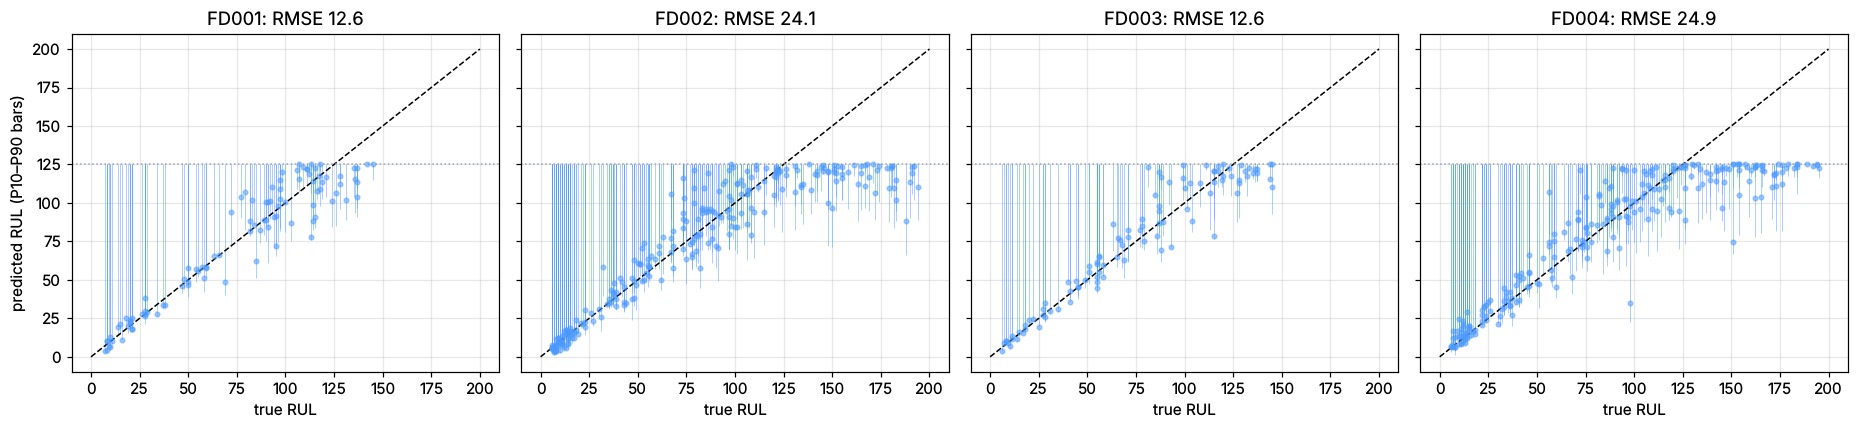

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, p in zip(axes, PROFILES):
    d = test_preds[p]
    ax.errorbar(d.true, d.pred, yerr=[d.pred - d.p10, d.p90 - d.pred], fmt="o", ms=3, alpha=.5, elinewidth=.6, color="#4C9AFF")
    ax.plot([0, 200], [0, 200], "k--", lw=1)
    ax.axhline(RUL_CAP, color="#9AA5B4", ls=":", lw=1)
    ax.set_title(f"{p}: RMSE {rmse(d.pred, d.true):.1f}"); ax.set_xlabel("true RUL")
axes[0].set_ylabel("predicted RUL (P10–P90 bars)")
plt.tight_layout(); plt.show()

Predictions flatten at the cap (125) for engines whose true RUL is above it — expected, and harmless for
maintenance decisions because those engines are far from any alert threshold. Errors are largest in that region.

In [18]:
# Error by true-RUL bucket: the region that matters for alerts is RUL ≤ 75.
rows = []
for p in PROFILES:
    d = test_preds[p].copy(); d["bucket"] = pd.cut(d.true, [0, 30, 75, 125, 1000], labels=["≤30", "31–75", "76–125", ">125"])
    for b, g in d.groupby("bucket", observed=True):
        rows.append({"profile": p, "true RUL": b, "engines": len(g), "RMSE": rmse(g.pred, g.true), "bias": float((g.pred - g.true).mean())})
pd.DataFrame(rows).pivot(index="profile", columns="true RUL", values="RMSE")[["≤30", "31–75", "76–125", ">125"]].round(1)

true RUL,≤30,31–75,76–125,>125
profile,,,,
FD001,3.8,7.9,14.5,20.7
FD002,3.2,12.6,13.9,46.7
FD003,3.0,7.6,15.9,18.2
FD004,6.0,14.6,15.2,43.0


In [19]:
# Alert confusion matrix on test engines (state from predicted vs. true RUL, thresholds 75 / 30).
def state(r): return np.where(r <= 30, "Critical", np.where(r <= 75, "Warning", "Healthy"))
order = ["Healthy", "Warning", "Critical"]
for p in PROFILES:
    d = test_preds[p]
    cm = pd.crosstab(pd.Categorical(state(d.true), order), pd.Categorical(state(d.pred), order),
                     rownames=["true"], colnames=[f"{p} predicted"], dropna=False)
    crit_recall = cm.loc["Critical", "Critical"] / max(cm.loc["Critical"].sum(), 1)
    false_crit = cm.loc["Healthy", "Critical"] / max(cm.loc["Healthy"].sum(), 1)
    display(cm); print(f"Critical recall {crit_recall:.2f} (target ≥ 0.90) · false Critical among healthy {false_crit:.2%} (target ≤ 5%)\n")

FD001 predicted,Healthy,Warning,Critical
true,,,
Healthy,55,2,0
Warning,1,16,1
Critical,0,1,24


Critical recall 0.96 (target ≥ 0.90) · false Critical among healthy 0.00% (target ≤ 5%)



FD002 predicted,Healthy,Warning,Critical
true,,,
Healthy,130,9,0
Warning,10,48,1
Critical,0,2,59


Critical recall 0.97 (target ≥ 0.90) · false Critical among healthy 0.00% (target ≤ 5%)



FD003 predicted,Healthy,Warning,Critical
true,,,
Healthy,49,2,0
Warning,5,23,1
Critical,0,2,18


Critical recall 0.90 (target ≥ 0.90) · false Critical among healthy 0.00% (target ≤ 5%)



FD004 predicted,Healthy,Warning,Critical
true,,,
Healthy,133,7,0
Warning,14,39,2
Critical,0,6,47


Critical recall 0.89 (target ≥ 0.90) · false Critical among healthy 0.00% (target ≤ 5%)



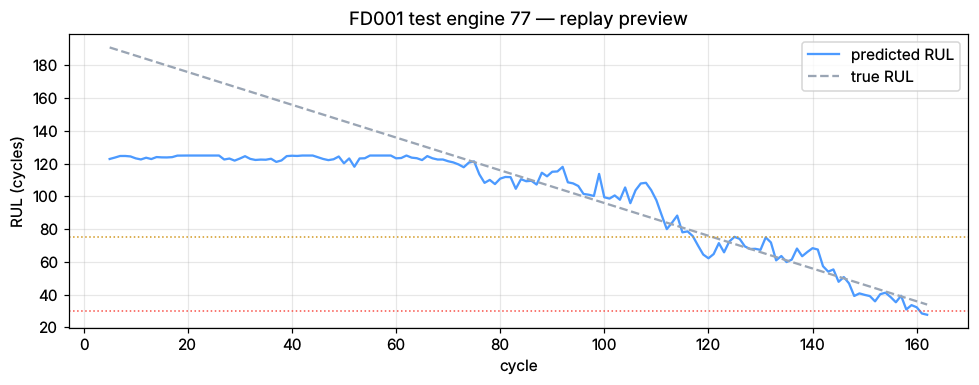

In [20]:
# What the dashboard will show: a predicted RUL trajectory for one test engine (as in Mode 1 replay).
p = "FD001"; cols = feature_cols(INPUTS[p])
# pick the engine at the 25th percentile of true RUL, so the replay crosses the Warning threshold
u = int(test_preds[p].true.sort_values().index[len(test_preds[p]) // 4])
Fte = build(p, train[p], test[p]); g = Fte[Fte.unit == u]
true_curve = true_rul[p].loc[u] + (g.cycle.max() - g.cycle)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(g.cycle, np.clip(final_models[p].predict(g[cols]), 0, RUL_CAP), label="predicted RUL", color="#4C9AFF")
ax.plot(g.cycle, true_curve, "--", color="#9AA5B4", label="true RUL")
ax.axhline(75, color="#D29922", ls=":", lw=1); ax.axhline(30, color="#F85149", ls=":", lw=1)
ax.set_xlabel("cycle"); ax.set_ylabel("RUL (cycles)"); ax.set_title(f"{p} test engine {u} — replay preview"); ax.legend()
plt.tight_layout(); plt.show()

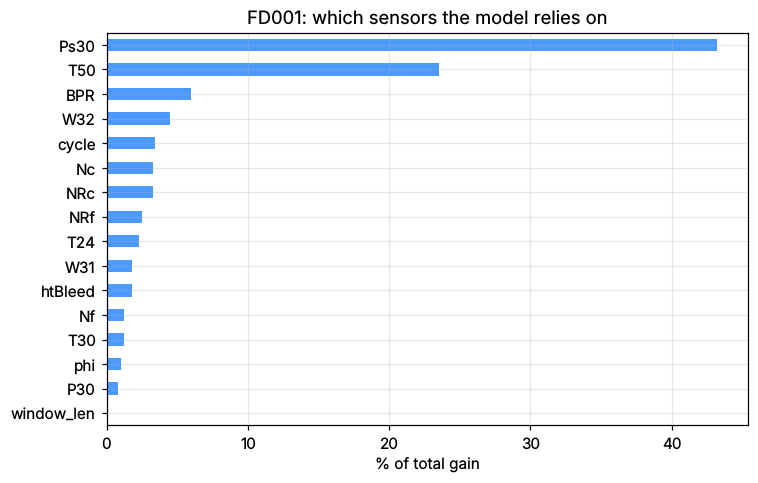

In [21]:
# Feature importance (gain), aggregated per sensor — feeds the "top contributors" idea in the detail report.
p = "FD001"
imp = pd.Series(final_models[p].feature_importance("gain"), index=final_models[p].feature_name())
by_sensor = imp.groupby(lambda c: c.split("_")[0] if c not in ("cycle", "window_len") else c).sum().sort_values()
ax = (by_sensor / by_sensor.sum() * 100).plot.barh(figsize=(7, 4.5), color="#4C9AFF")
ax.set_xlabel("% of total gain"); ax.set_title(f"{p}: which sensors the model relies on")
plt.tight_layout(); plt.show()

## 14. Write `data/reference/data_audit.json`

A machine-readable snapshot of the audit. `make audit` (plan step P1.4) will regenerate this file from
production code, and `docs/05_ML_and_Data_Spec.md` must agree with it.

In [22]:
def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

audit = {
    "generated_by": "ml/notebooks/01_data_audit_and_baseline.ipynb",
    "library_versions": {"pandas": pd.__version__, "numpy": np.__version__, "sklearn": sklearn.__version__, "lightgbm": lgb.__version__},
    "files": {f.name: sha256(f) for f in sorted(RAW.glob("*.txt"))},
    "quirks": [
        "readme lists 26 sensors; files contain 21 sensors (26 columns total)",
        "readme FD004 train/test counts swapped: actual 249 train, 248 test units",
        "rows have trailing whitespace; parse with sep=r'\\s+'",
    ],
    "profiles": {},
}
for p in PROFILES:
    tr = train[p]
    audit["profiles"][p] = {
        "train_rows": int(len(tr)), "test_rows": int(len(test[p])),
        "train_units": int(tr.unit.nunique()), "test_units": int(test[p].unit.nunique()),
        "train_life": {"min": int(life[p].min()), "median": float(life[p].median()), "max": int(life[p].max())},
        "test_length": {"min": int(test_len[p].min()), "median": float(test_len[p].median()), "max": int(test_len[p].max())},
        "true_test_rul": {"min": int(true_rul[p].min()), "median": float(true_rul[p].median()), "max": int(true_rul[p].max())},
        "constant_sensors": [s for s in SENSORS if tr[s].nunique() == 1],
        "model_inputs": INPUTS[p],
        "sensor_ranges": {s: {"min": float(tr[s].min()), "max": float(tr[s].max())} for s in SENSORS},
        "corr_with_capped_rul": {s: (None if pd.isna(v) else float(v)) for s, v in corr[p].items()},
        "cv_rmse": {"ridge": float(cv[p]["ridge"].mean()), "lightgbm": float(cv[p]["lgbm"].mean())},
        "test_metrics": {k: float(v) for k, v in test_results.loc[p, ["LightGBM RMSE", "Ridge RMSE", "NASA score", "P10–P90 coverage"]].items()},
    }
(REF / "data_audit.json").write_text(json.dumps(audit, indent=2))
print("wrote", REF / "data_audit.json")

wrote /tmp/repo/data/reference/data_audit.json


## 15. Conclusions

**Data**
* 4 subsets, 709 training and 707 test engines, clean (no gaps or missing values). Readme has two errors
  (21 sensors, not 26; FD004 counts swapped) — both recorded in `docs/05` §11.
* 14 base input sensors; +epr in multi-fault subsets; 7 sensors are constant, quantised or control setpoints.
* FD002/FD004 need regime-wise normalisation (6 flight conditions); FD003/FD004 have fault-mode-dependent
  sensor directions — keep those sensors.

**Modelling**
* Causal window features + capped target + LightGBM clearly beat the Ridge baseline (see sections 11–12).
* Results of this run (official test sets, last cycle): **FD001 RMSE 12.6, FD003 12.6** (targets ≤ 16 met, NASA scores 207 / 276);
  **FD002 24.1, FD004 24.9** (targets 22 / 24 narrowly missed). Section 13 shows why: engines with true RUL > 125
  dominate the error (RMSE ≈ 45 in that bucket) because the cap holds predictions at 125, while errors for RUL ≤ 30
  are only 3–6 cycles. The cap ablation {110, 125, 140} and grid search in plan step P1.6 are the planned fix.
* Alerting already looks strong: Critical recall 0.89–0.97 and **zero** healthy engines flagged Critical.
* Interval coverage from raw quantile models is usually below the 80% target, which is why `docs/05` §7.3
  specifies split-conformal widening.

**Next (from `docs/06_Plan.md`)**
* P1.5: move `RegimeNormalizer` and `window_features` into `ml/pdm_ml/features/` with a batch-vs-streaming parity test.
* P1.6–P1.9: full CV grid, conformal intervals, diagnostics, and versioned model bundles for the backend.